# `stochastics.popdyn` — population dynamics

Agent-based models where individuals have traits, interact locally, and the population-level picture emerges.
Every result has `.counts` (time series), `.agents` (one row per individual with traits and life history),
`.plot()` (a dashboard) and, for spatial models, `.animate()`. Where something is conserved (energy in the
ecosystem, wealth under exchange) there is a ledger that must close, and it is checked.

1. **Ecosystem** — grass → rabbits → wolves → grass, with heritable speed, vision and fertility
2. **Epidemic** — SIR/SEIR on a 2D world, with the full infection tree and superspreaders
3. **Rock-paper-scissors** — cyclic dominance on a lattice: spiral waves and the mobility threshold
4. **Wealth economy** — 10,000 people with traits; luck, talent, investment, trading and tax
5. **Schelling segregation** — mild preferences, strongly segregated outcome

In [1]:
import numpy as np
import pandas as pd
from stochastics.popdyn import *

## 1. Ecosystem: grass, rabbits, wolves

Rabbits look for grass and flee wolves they can see; wolves look for rabbits. Every animal burns energy
(more when it moves fast or sees far), breeds when it has enough energy, and passes its traits to its
children with small mutations, so the population evolves. Dead animals fertilise the ground, so grass grows
back from them and the loop closes. The energy ledger (sun + fertiliser in; digestion, metabolism and
detritus out) must balance to rounding error, and it does.

In [2]:
eco = Ecosystem(seed=7).run(steps=2000)
eco.totals()

,total
grass eaten by rabbits (items),3.407970e+05
grass eaten by rabbits (energy),1.022391e+06
rabbits eaten by wolves (items),9.441600e+04
rabbits eaten by wolves (energy),4.636316e+05
rabbit births,1.094420e+05
wolf births,1.658000e+03
rabbit deaths: starved,1.505700e+04
rabbit deaths: old age,1.900000e+01
rabbit deaths: eaten,9.441600e+04
wolf deaths: starved,1.187000e+03


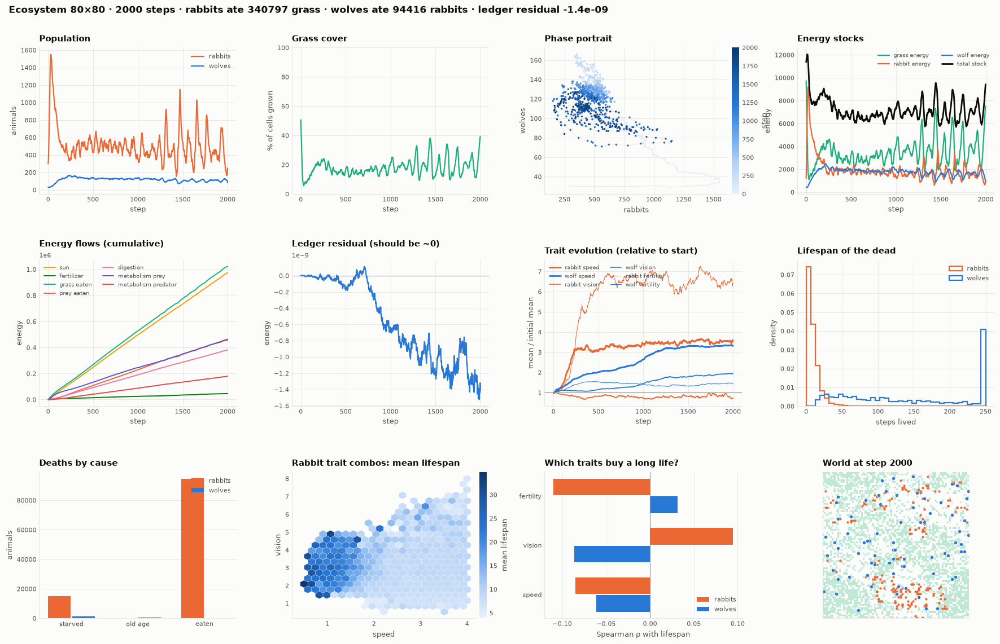

In [3]:
eco.plot()

In [20]:
eco.animate(max_frames=200)

**Who ate more?** The totals table above answers it in items and in energy. **Which rabbits did best?**
The longest-lived and the hungriest rabbits, with their traits, and how each trait relates to lifespan:

In [5]:
cols = ['generation', 'lifespan', 'cause', 'speed', 'vision', 'fertility', 'food', 'offspring']
display(eco.leaders('lifespan', 8, species='rabbit')[cols])
display(eco.leaders('food', 8, species='rabbit')[cols])
eco.trait_effects('rabbit', target='lifespan')

,generation,lifespan,cause,speed,vision,fertility,food,offspring
id,,,,,,,,
1885,2,120.0,old age,1.274509,3.371834,0.100233,30,4
493,1,120.0,old age,1.469860,2.253277,0.129392,32,5
2965,5,120.0,old age,1.334635,2.452040,0.189176,30,8
1783,5,120.0,old age,1.605179,3.385742,0.198763,41,9
1090,2,120.0,old age,1.251330,2.929711,0.175515,34,7
1629,2,120.0,old age,1.011407,3.233440,0.108542,26,3
863,1,120.0,old age,1.103570,3.057266,0.177260,24,5
1621,2,120.0,old age,0.966003,2.021021,0.123470,22,4


,generation,lifespan,cause,speed,vision,fertility,food,offspring
id,,,,,,,,
6266,9,100.0,eaten,2.531331,2.054800,0.256436,42,13
1783,5,120.0,old age,1.605179,3.385742,0.198763,41,9
16563,36,71.0,eaten,2.404496,2.230680,0.244210,37,8
604,2,107.0,eaten,1.187636,2.350730,0.174791,36,10
21630,51,97.0,starved,3.923043,3.123096,1.000000,36,14
3303,5,98.0,eaten,2.034535,2.149011,0.135535,36,8
1090,2,120.0,old age,1.251330,2.929711,0.175515,34,7
225,0,115.0,eaten,0.958878,2.316737,0.086515,34,6


,spearman_rho,p_value,top_vs_all_sd,mean_all,mean_top_10%
trait,,,,,
fertility,-0.110015,6.694121e-292,-0.566128,0.746239,0.612207
vision,0.094610,4.291817e-216,0.181472,2.430681,2.581693
speed,-0.085047,7.249536e-175,-0.526439,3.229412,2.839572


## 2. Epidemic with superspreaders

3,000 people wander a 2D world. Infectiousness is drawn from a skewed (gamma) distribution, so a minority
infects most others. Thick lines are the agents; thin lines are the classic well-mixed SIR equations with the
same parameters — the gap is the effect of space: people mostly meet neighbours who are already infected or
immune.

,value
metric,
people,3000
mean contacts within radius,1.36
R0 (well-mixed estimate),5.44
"early R (first 10% of cases, simulated)",1.97
ever infected,2744 (91%)
peak infectious,459 at t = 32.5
deaths,28
dispersion k (smaller = more superspreading),0.23
share of infections caused by top 20% of cases,84%


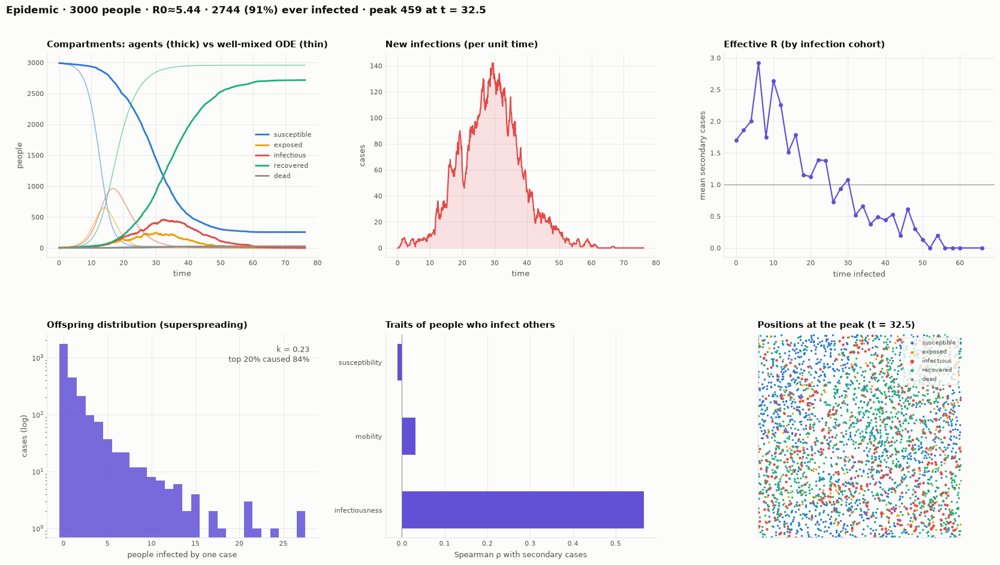

In [6]:
epi = Epidemic(n=3000, sigma=0.5, fatality=0.01, seed=3).run(80)
display(epi.summary())
epi.plot()

In [7]:
epi.animate(max_frames=45)

In [8]:
# the biggest spreaders and their traits
epi.leaders('secondary', 8)[['mobility', 'susceptibility', 'infectiousness', 'secondary', 'infected_at']]

,mobility,susceptibility,infectiousness,secondary,infected_at
id,,,,,
893,1.648307,1.965843,4.013755,27,11.2
1669,3.092038,1.020872,5.936928,27,23.5
2784,1.228321,1.186162,3.692993,24,24.2
196,0.929983,1.027096,4.349631,22,15.8
1636,2.422918,1.049040,11.492248,21,31.4
1518,1.523285,1.470640,3.059422,21,30.8
822,2.132991,1.200790,3.532809,21,19.4
215,0.877635,1.006051,5.714361,18,24.3


In [9]:
# mobility is a policy lever: same disease, different mixing
cols = ['ever infected', 'peak infectious', 'early R (first 10% of cases, simulated)']
pd.DataFrame({m: Epidemic(n=3000, mobility=m, seed=3).run(80).summary()['value'][cols]
              for m in (0.005, 0.03, 0.15)}).T.rename_axis('mobility')

metric,ever infected,peak infectious,"early R (first 10% of cases, simulated)"
mobility,,,
0.005,26 (1%),10 at t = 0.0,0.6
0.030,2767 (92%),566 at t = 20.2,1.42
0.150,2937 (98%),1260 at t = 12.0,2.21


## 3. Rock-paper-scissors: spirals keep everyone alive

Rock beats scissors, scissors beats paper, paper beats rock. In a well-mixed world the cycle drifts until one
species is left. On a lattice with little mobility, the cycle organises into rotating spiral waves that let
all three coexist; above a critical mobility (≈ 4.5 × 10⁻⁴) the spirals outgrow the world and diversity
collapses.

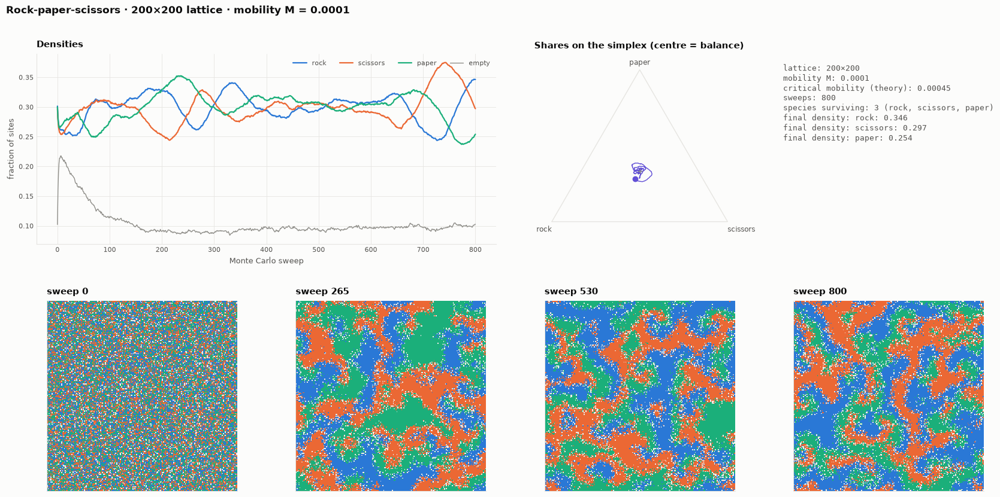

In [10]:
rps = RockPaperScissors(size=200, mobility=1e-4, seed=2).run(800)
rps.plot()

In [11]:
rps.animate(max_frames=50)

In [12]:
pd.DataFrame({M: RockPaperScissors(size=60, mobility=M, seed=3).run(3000, frame_every=3000).summary()['value']
              for M in (1e-4, 5e-3, 2e-2)}).T[['species surviving']].rename_axis('mobility M')

metric,species surviving
mobility M,
0.0001,"3 (rock, scissors, paper)"
0.0050,1 (paper)
0.0200,1 (paper)


## 4. Wealth: 10,000 people, traits and luck

Each person has talent, intelligence, creativity, charisma, luck, risk appetite and thrift (all editable via
`Trait`). Rules act each step (half a year):

* `LuckEvents` — lucky/unlucky events; a lucky break only pays off if you have the talent to seize it
  (Pluchino, Biondo & Rapisarda, *Talent vs Luck*, 2018);
* `Investment` — multiplicative returns; skill shifts the drift, risk appetite scales the volatility;
* `YardSale` — random pairs bet a share of the poorer one's wealth.

The wealth ledger (created − destroyed = change in total) closes to rounding error.

In [13]:
econ = Economy(n=10_000, rules=[LuckEvents(), Investment(), YardSale(stake=0.05)], seed=1).run(steps=80)
econ.summary()

,value
metric,
people,10000
rules,"LuckEvents, Investment, YardSale"
years simulated,40
total wealth,1e+05 -> 7.695e+05
Gini,0.000 -> 0.909
top 1% share,1.0% -> 53.3%
bottom 50% share,50.0% -> 0.9%
richest person / median,5.66e+03x
Pareto tail alpha (top 1%),1.13


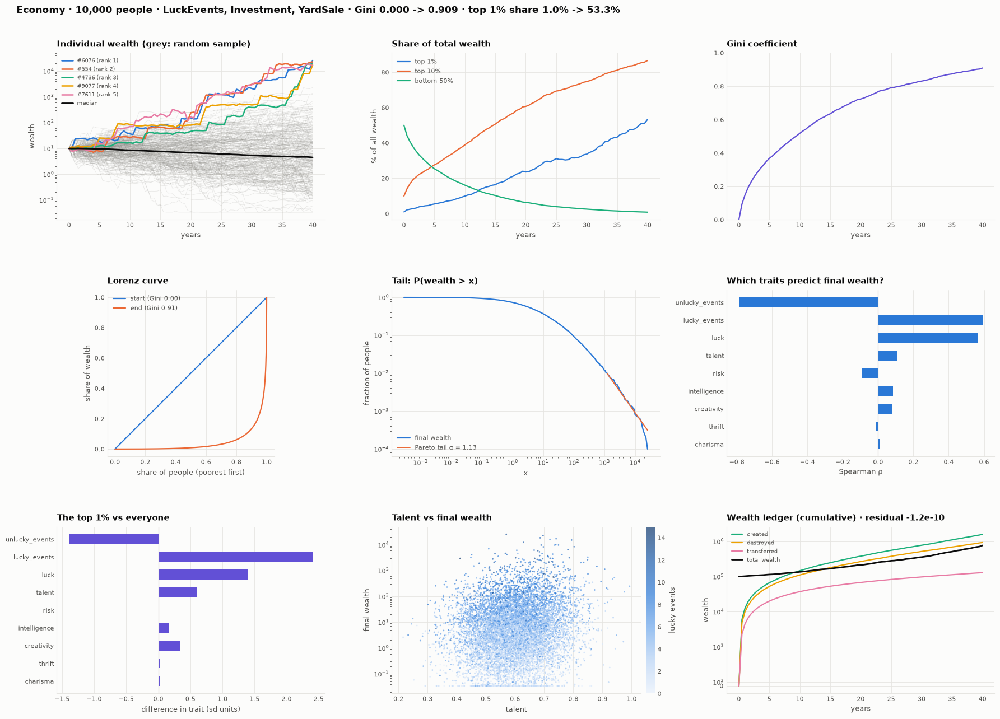

In [14]:
econ.plot()

**Is there anyone with a trait set that made them richer than everyone else?** The richest ten, with their
traits and how many lucky / unlucky events they had, then the population-wide trait effects:

In [15]:
display(econ.leaders(10).round(2))
econ.trait_effects().round(3)

,rank,final,initial,peak,talent,intelligence,creativity,charisma,luck,risk,thrift,lucky_events,unlucky_events
id,,,,,,,,,,,,,
6076,1,25504.83,10.0,25504.83,0.57,90.13,0.86,-1.04,0.86,1.36,0.37,13,0
554,2,22578.17,10.0,22578.17,0.70,70.68,0.87,0.45,0.82,0.93,0.11,11,0
4736,3,18590.18,10.0,18590.18,0.69,111.89,0.52,-0.16,0.78,0.94,0.30,11,0
9077,4,17020.16,10.0,17020.16,0.74,113.90,0.16,-1.31,0.75,0.93,0.52,10,0
7611,5,16177.94,10.0,18559.69,0.72,97.02,0.37,-1.65,0.78,2.13,0.53,7,1
5404,6,15232.26,10.0,15232.26,0.79,77.52,0.52,-0.10,0.67,1.54,0.09,10,0
4406,7,12312.71,10.0,12312.71,0.63,100.47,0.69,0.05,0.63,1.44,0.43,12,0
7815,8,10039.91,10.0,10129.66,0.74,95.31,0.82,0.68,0.86,0.57,0.23,9,0
8633,9,9747.25,10.0,9747.25,0.75,94.95,0.82,0.93,0.68,1.54,0.07,9,0


,spearman_rho,p_value,top_vs_all_sd,mean_all,mean_top_1%
trait,,,,,
unlucky_events,-0.788,0.000,-1.392,4.006,0.820
lucky_events,0.591,0.000,2.406,3.982,9.550
luck,0.563,0.000,1.397,0.498,0.708
talent,0.108,0.000,0.600,0.599,0.659
risk,-0.090,0.000,0.011,1.002,1.007
intelligence,0.084,0.000,0.164,99.825,102.258
creativity,0.082,0.000,0.334,0.500,0.574
thrift,-0.009,0.345,0.023,0.290,0.293
charisma,0.007,0.471,0.018,0.003,0.021


The richest are rarely the most talented: they are moderately talented people who had many lucky breaks and
almost no unlucky ones. Talent matters (positive ρ), luck matters far more.

### Policy experiments
Same population, different rules. Pure exchange conserves wealth exactly; tax redistributes it; luck and
investment create and destroy it.

In [16]:
setups = {
    'kinetic exchange (savings)': [KineticExchange()],
    'yard sale': [YardSale()],
    'yard sale + 2% wealth tax': [YardSale(), Tax(0.02)],
    'luck': [LuckEvents()],
    'luck + investment + 1% tax': [LuckEvents(), Investment(), Tax(0.01)],
    'wages + investment + spending': [Wages(), Investment(), Consumption()],
}
cols = ['Gini', 'top 1% share', 'bottom 50% share', 'Pareto tail alpha (top 1%)', 'ledger residual']
pd.DataFrame({name: Economy(n=10_000, rules=rules, seed=2).run(100).summary()['value'][cols]
              for name, rules in setups.items()}).T

metric,Gini,top 1% share,bottom 50% share,Pareto tail alpha (top 1%),ledger residual
kinetic exchange (savings),0.000 -> 0.387,1.0% -> 4.0%,50.0% -> 22.9%,6.18,+0.00e+00
yard sale,0.000 -> 0.424,1.0% -> 3.9%,50.0% -> 19.9%,10.27,+0.00e+00
yard sale + 2% wealth tax,0.000 -> 0.287,1.0% -> 2.8%,50.0% -> 29.6%,11.09,-7.28e-11
luck,0.000 -> 0.913,1.0% -> 50.4%,50.0% -> 0.7%,1.92,+0.00e+00
luck + investment + 1% tax,0.000 -> 0.835,1.0% -> 51.6%,50.0% -> 4.7%,1.12,-9.31e-10
wages + investment + spending,0.000 -> 0.407,1.0% -> 6.9%,50.0% -> 22.8%,3.00,-9.90e-10


Write your own rule with one method, `apply(market)`, that changes `market.wealth` and returns the flows:

In [17]:
class Inheritance:
    # people from wealthy families get a yearly transfer from outside the economy
    def apply(self, m):
        gift = 0.02 * m.wealth * m.dt * (m.traits['family'] > 0.9)
        m.wealth += gift
        return {'created': gift.sum()}

traits = [*DEFAULT_TRAITS, Trait('family', 'uniform', 0, 1)]
econ2 = Economy(n=10_000, traits=traits, rules=[Inheritance(), LuckEvents(), Investment()], seed=4).run(80)
econ2.trait_effects().round(3).loc[['luck', 'family', 'talent', 'intelligence']]

,spearman_rho,p_value,top_vs_all_sd,mean_all,mean_top_1%
trait,,,,,
luck,0.557,0.0,1.313,0.501,0.699
family,0.053,0.0,0.112,0.504,0.536
talent,0.116,0.0,0.579,0.602,0.659
intelligence,0.074,0.0,0.210,100.086,103.250


## 5. Schelling segregation

Two groups; everyone is content as long as at least 35% of their neighbours are like them (they would happily
be a minority). Discontent people move. The town still sorts itself into large single-group blocks.

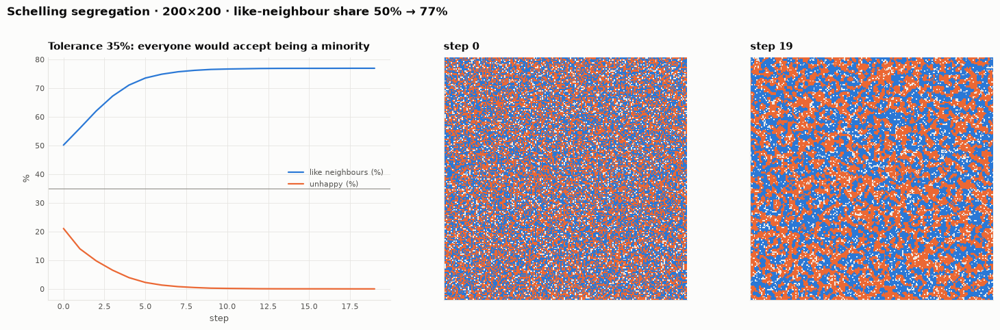

In [21]:
seg = Schelling(size=200, tolerance=0.35, seed=3).run(400)
seg.plot()

In [22]:
seg.animate()

## More models to build on this

* **Sugarscape** (Epstein & Axtell) — agents with vision and metabolism harvest a renewable landscape:
  wealth inequality from ecology; a natural bridge between the ecosystem and the economy here.
* **Opinion dynamics** — voter model, bounded confidence (Deffuant / Hegselmann–Krause): polarisation and
  consensus; the seed for the social-media attention model.
* **Evolutionary games** — prisoner's dilemma on a lattice: when does cooperation survive?
* **Kinetic wealth with debt** — let wealth go negative (credit) and add bankruptcy.
* **Fitting** — calibrate rule parameters to real distributions (wealth surveys, case counts) with
  approximate Bayesian computation.